# Superstore Sales Analysis

**Project type:** Exploratory Data Analysis (EDA)  
**Tools:** Python, Pandas, Matplotlib, Seaborn  
**Dataset:** Superstore Sales

## Project overview

This project analyses retail transactions to understand sales performance, profitability, customer purchasing behaviour, regional performance, discount sensitivity and monthly seasonality.

## Business questions

1. What are the overall revenue, profit and order performance?
2. Which product categories and subcategories contribute most to revenue and profit?
3. Which regions and customer segments perform best?
4. Which customers generate the highest sales and profit, and which generate losses?
5. How are discounts associated with transaction profitability?
6. Which months show stronger or weaker sales and profit performance?

**Important:** This notebook is designed to be run from top to bottom. Run each code cell in order after opening the notebook.


## 1. Import libraries and load the dataset

The dataset is expected in the project folder at `data/superstore_sales.csv`. If that relative path is not available, the code also checks the original Windows location used in the earlier notebook.


In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

print("Libraries imported successfully.")

DATA_PATH = Path("data") / "superstore_sales.csv"

if not DATA_PATH.exists():
    DATA_PATH = Path(
        r"C:\Users\Arshad Muhammed\Documents\Superstore-Sales-Analysis\data\superstore_sales.csv"
    )

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Dataset not found. Place superstore_sales.csv inside the project's "
        "'data' folder or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Original dataset shape:", df.shape)
df.head()


Libraries imported successfully.
Dataset loaded successfully.
Original dataset shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


## 2. Initial data inspection

Inspect the dataset structure, column names, data types, missing values, duplicates and numerical distributions before cleaning.


In [3]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Dataset shape: (10800, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  str    
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  P

In [4]:
missing_values = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "missing_percentage": (df.isna().sum() / len(df) * 100).round(2)
}).sort_values("missing_values", ascending=False)

display(missing_values)
print("Exact duplicate rows in original data:", df.duplicated().sum())


,missing_values,missing_percentage
Postal Code,817,7.56
Ship Mode,806,7.46
Ship Date,806,7.46
Customer ID,806,7.46
Order Date,806,7.46
Product ID,806,7.46
Category,806,7.46
Segment,806,7.46
Customer Name,806,7.46
Country,806,7.46


Exact duplicate rows in original data: 504


In [5]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Row ID,10800,10001,Yes,800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order ID,10800,5015,CA-2018-100111,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,1236,9/5/2017,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9994,1334,12/16/2016,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data cleaning

The source file contains 10,800 rows. The initial inspection identified 806 records without a valid order date. These records are excluded from the analytical dataset because they do not contain the date and transaction details required for this sales analysis.

The remaining valid dataset should contain 9,994 records. Missing postal codes in otherwise valid records are retained because postal code is not required for the analyses in this project.


In [6]:
# Create a separate working copy
df_clean = df.copy()

# Standardise column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

# Convert date columns
date_columns = [col for col in df_clean.columns if "date" in col]

for col in date_columns:
    df_clean[col] = pd.to_datetime(df_clean[col], errors="coerce")

print("Date columns converted:", date_columns)
print("Rows with missing order dates:", df_clean["order_date"].isna().sum())


Date columns converted: ['order_date', 'ship_date']
Rows with missing order dates: 806


In [7]:
# Inspect incomplete records before removing them
incomplete_rows = df_clean[df_clean["order_date"].isna()]

print("Incomplete records:", len(incomplete_rows))
print("\nNon-missing values in incomplete records:")
display(incomplete_rows.notna().sum())

display(incomplete_rows[["row_id", "order_id"]].head(10))


Incomplete records: 806

Non-missing values in incomplete records:


row_id           806
order_id         806
order_date         0
ship_date          0
ship_mode          0
customer_id        0
customer_name      0
segment            0
country            0
city               0
state              0
postal_code        0
region             0
product_id         0
category           0
sub_category       0
product_name       0
sales              0
quantity           0
discount           0
profit             0
dtype: int64

,row_id,order_id
9994,Person,Region
9995,Anna Andreadi,West
9996,Chuck Magee,East
9997,Kelly Williams,Central
9998,Cassandra Brandow,South
9999,Returned,Order ID
10000,Yes,CA-2015-100762
10001,Yes,CA-2015-100762
10002,Yes,CA-2015-100762
10003,Yes,CA-2015-100762


In [8]:
# Keep records with valid order dates
df_clean = df_clean.dropna(subset=["order_date"]).copy()

# Reset the index without using inplace
df_clean = df_clean.reset_index(drop=True)

print("Cleaned dataset shape:", df_clean.shape)
print("\nMissing values after removing invalid-date records:")
display(df_clean.isna().sum())


Cleaned dataset shape: (9994, 21)

Missing values after removing invalid-date records:


row_id            0
order_id          0
order_date        0
ship_date         0
ship_mode         0
customer_id       0
customer_name     0
segment           0
country           0
city              0
state             0
postal_code      11
region            0
product_id        0
category          0
sub_category      0
product_name      0
sales             0
quantity          0
discount          0
profit            0
dtype: int64

In [9]:
print("Exact duplicate rows:", df_clean.duplicated().sum())
print("Duplicate Row IDs:", df_clean["row_id"].duplicated().sum())

numerical_columns = ["sales", "quantity", "discount", "profit"]
display(df_clean[numerical_columns].describe().round(2))

print("Negative sales:", (df_clean["sales"] < 0).sum())
print("Non-positive quantities:", (df_clean["quantity"] <= 0).sum())
print("Loss-making transaction line items:", (df_clean["profit"] < 0).sum())
print("Minimum discount:", df_clean["discount"].min())
print("Maximum discount:", df_clean["discount"].max())


Exact duplicate rows: 0
Duplicate Row IDs: 0


,sales,quantity,discount,profit
count,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98


Negative sales: 0
Non-positive quantities: 0
Loss-making transaction line items: 1871
Minimum discount: 0.0
Maximum discount: 0.8


## 4. Feature engineering

Create date features for time-based analysis, calculate transaction-level profit margin, and group discounts into descriptive bands.


In [10]:
df_clean["year"] = df_clean["order_date"].dt.year
df_clean["month"] = df_clean["order_date"].dt.month
df_clean["month_name"] = df_clean["order_date"].dt.month_name()
df_clean["year_month"] = df_clean["order_date"].dt.to_period("M")

df_clean["profit_margin"] = (
    df_clean["profit"] /
    df_clean["sales"].replace(0, np.nan)
) * 100

df_clean["discount_level"] = pd.cut(
    df_clean["discount"],
    bins=[-0.001, 0, 0.1, 0.2, 0.3, 1],
    labels=[
        "No Discount",
        "Low Discount",
        "Moderate Discount",
        "High Discount",
        "Very High Discount"
    ]
)

print("Feature engineering completed.")
print("Final dataset shape:", df_clean.shape)
display(df_clean.head())


Feature engineering completed.
Final dataset shape: (9994, 27)


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,sales,quantity,discount,profit,year,month,month_name,year_month,profit_margin,discount_level
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,261.9600,2.0,0.00,41.9136,2017,11,November,2017-11,16.00,No Discount
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,731.9400,3.0,0.00,219.5820,2017,11,November,2017-11,30.00,No Discount
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,14.6200,2.0,0.00,6.8714,2017,6,June,2017-06,47.00,No Discount
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,957.5775,5.0,0.45,-383.0310,2016,10,October,2016-10,-40.00,Very High Discount
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,22.3680,2.0,0.20,2.5164,2016,10,October,2016-10,11.25,Moderate Discount


## 5. Executive overview

Calculate the main business KPIs. The loss-making transaction percentage is calculated at the **transaction line-item level**, not by unique order.


In [11]:
total_revenue = df_clean["sales"].sum()
total_profit = df_clean["profit"].sum()
total_orders = df_clean["order_id"].nunique()
total_customers = df_clean["customer_id"].nunique()
total_units = df_clean["quantity"].sum()
profit_margin = (total_profit / total_revenue) * 100
average_order_value = total_revenue / total_orders
loss_line_items = (df_clean["profit"] < 0).sum()
loss_line_item_rate = (loss_line_items / len(df_clean)) * 100

executive_summary = pd.DataFrame({
    "Metric": [
        "Total Revenue",
        "Total Profit",
        "Profit Margin (%)",
        "Total Orders",
        "Total Customers",
        "Total Units Sold",
        "Average Order Value",
        "Loss-Making Transaction Line Items (%)"
    ],
    "Value": [
        total_revenue,
        total_profit,
        profit_margin,
        total_orders,
        total_customers,
        total_units,
        average_order_value,
        loss_line_item_rate
    ]
})

display(executive_summary.round(2))


,Metric,Value
0,Total Revenue,2297200.86
1,Total Profit,286397.02
2,Profit Margin (%),12.47
3,Total Orders,5009.00
4,Total Customers,793.00
5,Total Units Sold,37873.00
6,Average Order Value,458.61
7,Loss-Making Transaction Line Items (%),18.72


## 6. Product performance analysis

### 6.1 Category analysis

Compare revenue, profit, units sold, order volume, average discount and profit margin across product categories.


In [12]:
category_analysis = (
    df_clean.groupby("category")
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        units_sold=("quantity", "sum"),
        total_orders=("order_id", "nunique"),
        average_discount=("discount", "mean")
    )
    .reset_index()
)

category_analysis["profit_margin_%"] = (
    category_analysis["total_profit"] /
    category_analysis["total_sales"] * 100
).round(2)

category_analysis["revenue_contribution_%"] = (
    category_analysis["total_sales"] /
    category_analysis["total_sales"].sum() * 100
).round(2)

category_analysis = category_analysis.sort_values(
    "total_sales", ascending=False
)

display(category_analysis.round(2))


,category,total_sales,total_profit,units_sold,total_orders,average_discount,profit_margin_%,revenue_contribution_%
2,Technology,836154.03,145454.95,6939.0,1544,0.13,17.40,36.4
0,Furniture,741999.80,18451.27,8028.0,1764,0.17,2.49,32.3
1,Office Supplies,719047.03,122490.80,22906.0,3742,0.16,17.04,31.3


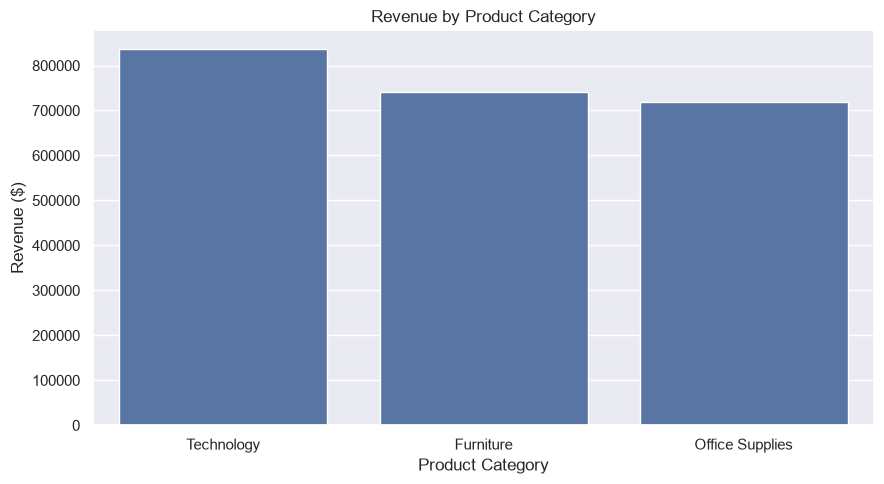

In [13]:
plt.figure(figsize=(9, 5))
sns.barplot(data=category_analysis, x="category", y="total_sales")
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue ($)")
plt.tight_layout()
plt.show()


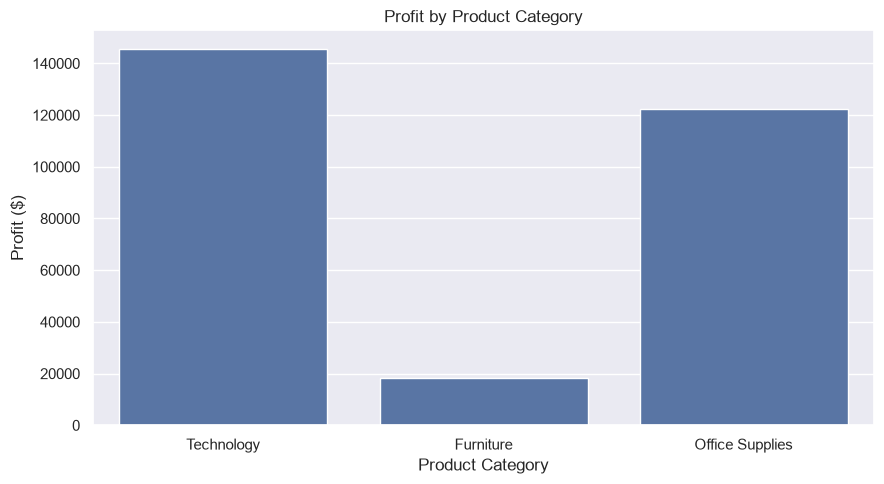

In [14]:
plt.figure(figsize=(9, 5))
sns.barplot(data=category_analysis, x="category", y="total_profit")
plt.title("Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Profit ($)")
plt.tight_layout()
plt.show()


### 6.2 Subcategory analysis

Compare the performance of individual subcategories and identify the strongest and weakest contributors to profit.


In [15]:
subcategory_analysis = (
    df_clean.groupby(["category", "sub_category"])
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        units_sold=("quantity", "sum"),
        total_orders=("order_id", "nunique"),
        average_discount=("discount", "mean")
    )
    .reset_index()
)

subcategory_analysis["profit_margin_%"] = (
    subcategory_analysis["total_profit"] /
    subcategory_analysis["total_sales"] * 100
).round(2)

print("Top 5 subcategories by profit")
display(subcategory_analysis.nlargest(5, "total_profit").round(2))

print("Bottom 5 subcategories by profit")
display(subcategory_analysis.nsmallest(5, "total_profit").round(2))


Top 5 subcategories by profit


,category,sub_category,total_sales,total_profit,units_sold,total_orders,average_discount,profit_margin_%
14,Technology,Copiers,149528.03,55617.82,234.0,68,0.16,37.20
16,Technology,Phones,330007.05,44515.73,3289.0,814,0.15,13.49
13,Technology,Accessories,167380.32,41936.64,2976.0,718,0.08,25.05
10,Office Supplies,Paper,78479.21,34053.57,5178.0,1191,0.07,43.39
6,Office Supplies,Binders,203412.73,30221.76,5974.0,1316,0.37,14.86


Bottom 5 subcategories by profit


,category,sub_category,total_sales,total_profit,units_sold,total_orders,average_discount,profit_margin_%
3,Furniture,Tables,206965.53,-17725.48,1241.0,307,0.26,-8.56
0,Furniture,Bookcases,114880.00,-3472.56,868.0,224,0.21,-3.02
12,Office Supplies,Supplies,46673.54,-1189.10,647.0,187,0.08,-2.55
8,Office Supplies,Fasteners,3024.28,949.52,914.0,215,0.08,31.40
15,Technology,Machines,189238.63,3384.76,440.0,112,0.31,1.79


## 7. Customer segment analysis

Compare revenue, profit, order volume, quantity and profit margin across Consumer, Corporate and Home Office segments.


In [16]:
segment_analysis = (
    df_clean.groupby("segment")
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        total_orders=("order_id", "nunique"),
        total_quantity=("quantity", "sum")
    )
    .reset_index()
)

segment_analysis["profit_margin_%"] = (
    segment_analysis["total_profit"] /
    segment_analysis["total_sales"] * 100
).round(2)

display(segment_analysis.sort_values("total_sales", ascending=False).round(2))


,segment,total_sales,total_profit,total_orders,total_quantity,profit_margin_%
0,Consumer,1161401.34,134119.21,2586,19521.0,11.55
1,Corporate,706146.37,91979.13,1514,11608.0,13.03
2,Home Office,429653.15,60298.68,909,6744.0,14.03


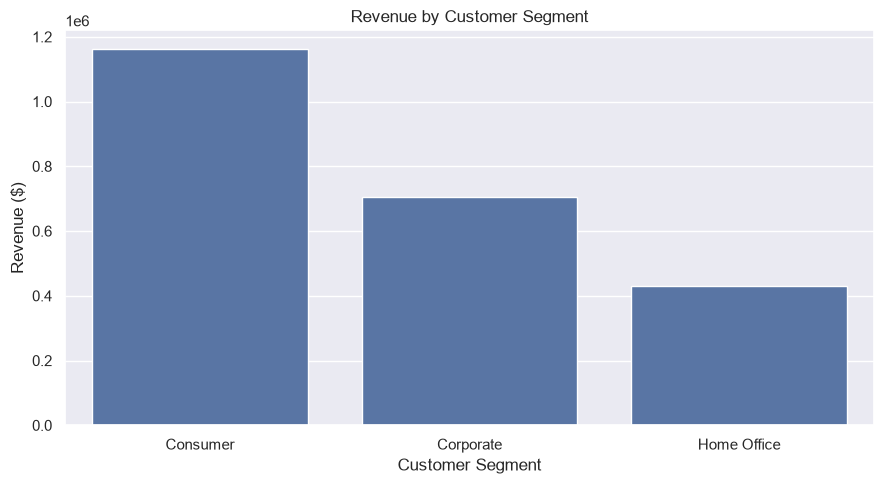

In [17]:
plt.figure(figsize=(9, 5))
sns.barplot(data=segment_analysis, x="segment", y="total_sales")
plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue ($)")
plt.tight_layout()
plt.show()


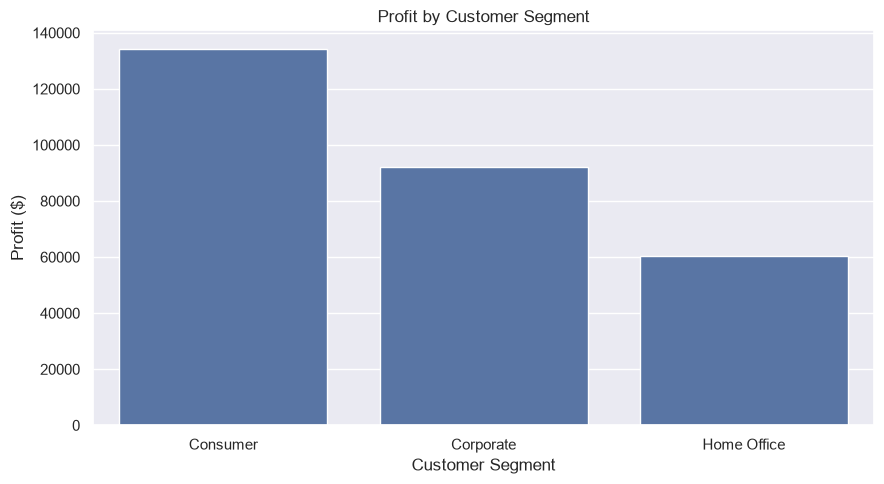

In [18]:
plt.figure(figsize=(9, 5))
sns.barplot(data=segment_analysis, x="segment", y="total_profit")
plt.title("Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Profit ($)")
plt.tight_layout()
plt.show()


## 8. Regional performance analysis

Compare revenue, profit, order volume, quantity, average discount and profit margin across regions.


In [19]:
region_analysis = (
    df_clean.groupby("region")
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        total_orders=("order_id", "nunique"),
        total_quantity=("quantity", "sum"),
        average_discount=("discount", "mean")
    )
    .reset_index()
)

region_analysis["profit_margin_%"] = (
    region_analysis["total_profit"] /
    region_analysis["total_sales"] * 100
).round(2)

region_analysis["revenue_contribution_%"] = (
    region_analysis["total_sales"] /
    region_analysis["total_sales"].sum() * 100
).round(2)

region_analysis = region_analysis.sort_values("total_sales", ascending=False)
display(region_analysis.round(2))


,region,total_sales,total_profit,total_orders,total_quantity,average_discount,profit_margin_%,revenue_contribution_%
3,West,725457.82,108418.45,1611,12266.0,0.11,14.94,31.58
1,East,678781.24,91522.78,1401,10618.0,0.15,13.48,29.55
0,Central,501239.89,39706.36,1175,8780.0,0.24,7.92,21.82
2,South,391721.90,46749.43,822,6209.0,0.15,11.93,17.05


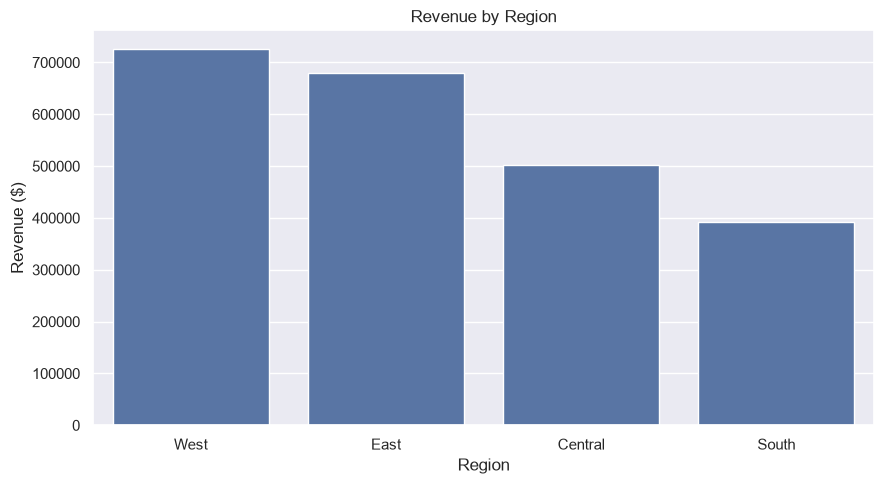

In [20]:
plt.figure(figsize=(9, 5))
sns.barplot(data=region_analysis, x="region", y="total_sales")
plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue ($)")
plt.tight_layout()
plt.show()


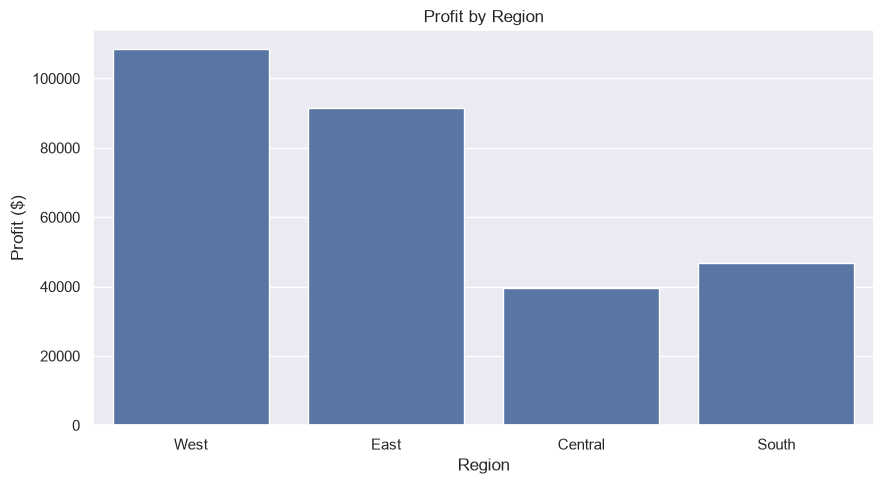

In [21]:
plt.figure(figsize=(9, 5))
sns.barplot(data=region_analysis, x="region", y="total_profit")
plt.title("Profit by Region")
plt.xlabel("Region")
plt.ylabel("Profit ($)")
plt.tight_layout()
plt.show()


## 9. Customer purchasing behaviour and profitability

### 9.1 Customer spending and order frequency

Aggregate sales, profit, unique orders, units and average discount for each customer.


In [22]:
customer_analysis = (
    df_clean.groupby(["customer_id", "customer_name"])
    .agg(
        total_orders=("order_id", "nunique"),
        total_spending=("sales", "sum"),
        total_profit=("profit", "sum"),
        total_units=("quantity", "sum"),
        average_discount=("discount", "mean")
    )
    .reset_index()
)

top_10_customers = customer_analysis.nlargest(10, "total_spending")
display(top_10_customers.round(2))


,customer_id,customer_name,total_orders,total_spending,total_profit,total_units,average_discount
700,SM-20320,Sean Miller,5,25043.05,-1980.74,50.0,0.25
741,TC-20980,Tamara Chand,5,19052.22,8981.32,42.0,0.12
621,RB-19360,Raymond Buch,6,15117.34,6976.10,71.0,0.09
730,TA-21385,Tom Ashbrook,4,14595.62,4703.79,36.0,0.08
6,AB-10105,Adrian Barton,10,14473.57,5444.81,73.0,0.24
434,KL-16645,Ken Lonsdale,12,14175.23,806.86,113.0,0.20
669,SC-20095,Sanjit Chand,9,14142.33,5757.41,87.0,0.06
327,HL-15040,Hunter Lopez,6,12873.30,5622.43,50.0,0.02
683,SE-20110,Sanjit Engle,11,12209.44,2650.68,78.0,0.11
131,CC-12370,Christopher Conant,5,12129.07,2177.05,34.0,0.28


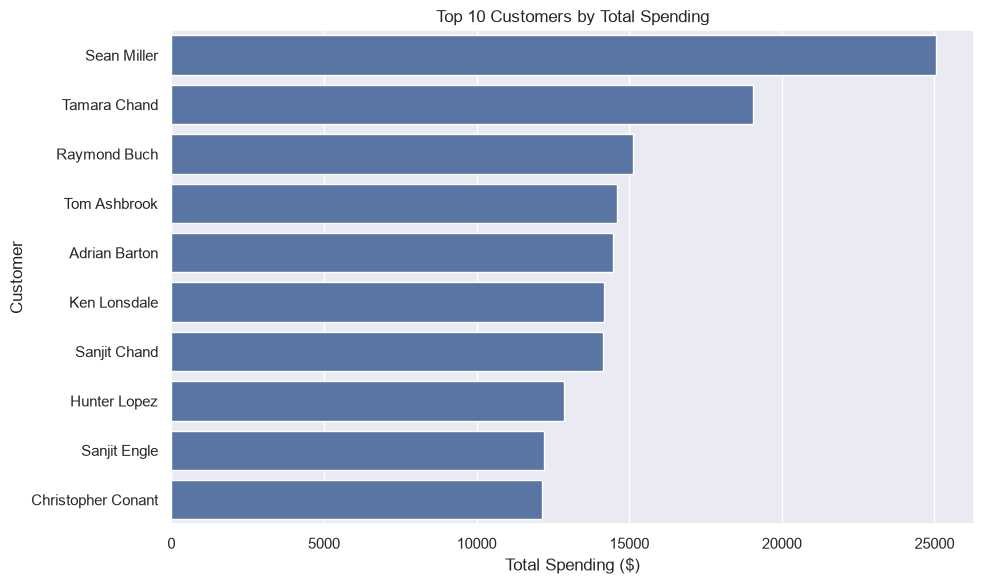

In [23]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_10_customers,
    x="total_spending",
    y="customer_name"
)
plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Total Spending ($)")
plt.ylabel("Customer")
plt.tight_layout()
plt.show()


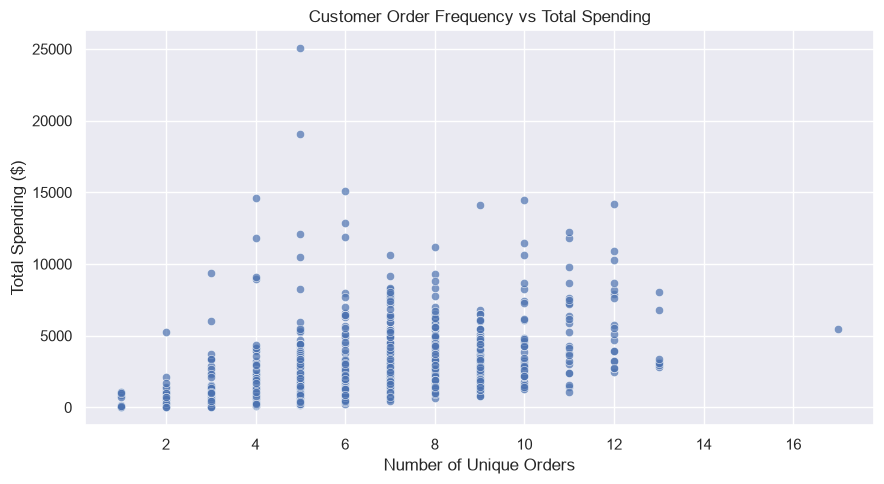

In [24]:
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=customer_analysis,
    x="total_orders",
    y="total_spending",
    alpha=0.7
)
plt.title("Customer Order Frequency vs Total Spending")
plt.xlabel("Number of Unique Orders")
plt.ylabel("Total Spending ($)")
plt.tight_layout()
plt.show()


### 9.2 Most and least profitable customers

High sales do not always mean high profitability. Compare customers by total profit contribution.


In [25]:
top_profit_customers = customer_analysis.nlargest(10, "total_profit")
lowest_profit_customers = customer_analysis.nsmallest(10, "total_profit")

print("Top 10 most profitable customers")
display(top_profit_customers.round(2))

print("10 customers with the lowest total profit")
display(lowest_profit_customers.round(2))


Top 10 most profitable customers


,customer_id,customer_name,total_orders,total_spending,total_profit,total_units,average_discount
741,TC-20980,Tamara Chand,5,19052.22,8981.32,42.0,0.12
621,RB-19360,Raymond Buch,6,15117.34,6976.10,71.0,0.09
669,SC-20095,Sanjit Chand,9,14142.33,5757.41,87.0,0.06
327,HL-15040,Hunter Lopez,6,12873.30,5622.43,50.0,0.02
6,AB-10105,Adrian Barton,10,14473.57,5444.81,73.0,0.24
730,TA-21385,Tom Ashbrook,4,14595.62,4703.79,36.0,0.08
160,CM-12385,Christopher Martinez,4,8954.02,3899.89,34.0,0.12
424,KD-16495,Keith Dawkins,12,8181.26,3038.63,84.0,0.09
48,AR-10540,Andy Reiter,6,6608.45,2884.62,33.0,0.07
234,DR-12940,Daniel Raglin,8,8350.87,2869.08,57.0,0.15


10 customers with the lowest total profit


,customer_id,customer_name,total_orders,total_spending,total_profit,total_units,average_discount
180,CS-12505,Cindy Stewart,6,5690.05,-6626.39,40.0,0.20
310,GT-14635,Grant Thornton,3,9351.21,-4108.66,26.0,0.25
459,LF-17185,Luke Foster,7,3930.51,-3583.98,69.0,0.32
711,SR-20425,Sharelle Roach,5,3233.48,-3333.91,34.0,0.37
322,HG-14965,Henry Goldwyn,12,3247.64,-2797.96,68.0,0.17
555,NC-18415,Nathan Cano,6,2218.99,-2204.81,38.0,0.26
666,SB-20290,Sean Braxton,7,8057.89,-2082.75,84.0,0.24
700,SM-20320,Sean Miller,5,25043.05,-1980.74,50.0,0.25
165,CP-12340,Christine Phan,8,5888.28,-1850.30,59.0,0.21
560,NF-18385,Natalie Fritzler,7,8322.83,-1695.97,52.0,0.25


## 10. Discount sensitivity analysis

The first analysis groups transactions by their exact discount rate. It calculates total sales, total profit, average profit and the proportion of transaction line items that made a loss.


In [26]:
discount_analysis = (
    df_clean.groupby("discount")
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        average_profit=("profit", "mean"),
        transactions=("profit", "count"),
        loss_transactions=("profit", lambda values: (values < 0).sum())
    )
    .reset_index()
)

discount_analysis["profit_margin_%"] = (
    discount_analysis["total_profit"] /
    discount_analysis["total_sales"] * 100
).round(2)

discount_analysis["loss_rate_%"] = (
    discount_analysis["loss_transactions"] /
    discount_analysis["transactions"] * 100
).round(2)

discount_analysis = discount_analysis.sort_values("discount")
display(discount_analysis.round(2))


,discount,total_sales,total_profit,average_profit,transactions,loss_transactions,profit_margin_%,loss_rate_%
0,0.00,1087908.47,320987.60,66.90,4798,0,29.51,0.00
1,0.10,54369.35,9029.18,96.06,94,4,16.61,4.26
2,0.15,27558.52,1418.99,27.29,52,17,5.15,32.69
3,0.20,764594.37,90337.31,24.70,3657,502,11.82,13.73
4,0.30,103226.66,-10369.28,-45.68,227,208,-10.05,91.63
5,0.32,14493.46,-2391.14,-88.56,27,27,-16.50,100.00
6,0.40,116417.78,-23057.05,-111.93,206,180,-19.81,87.38
7,0.45,5484.97,-2493.11,-226.65,11,11,-45.45,100.00
8,0.50,58918.54,-20506.43,-310.70,66,66,-34.80,100.00
9,0.60,6644.70,-5944.66,-43.08,138,138,-89.46,100.00


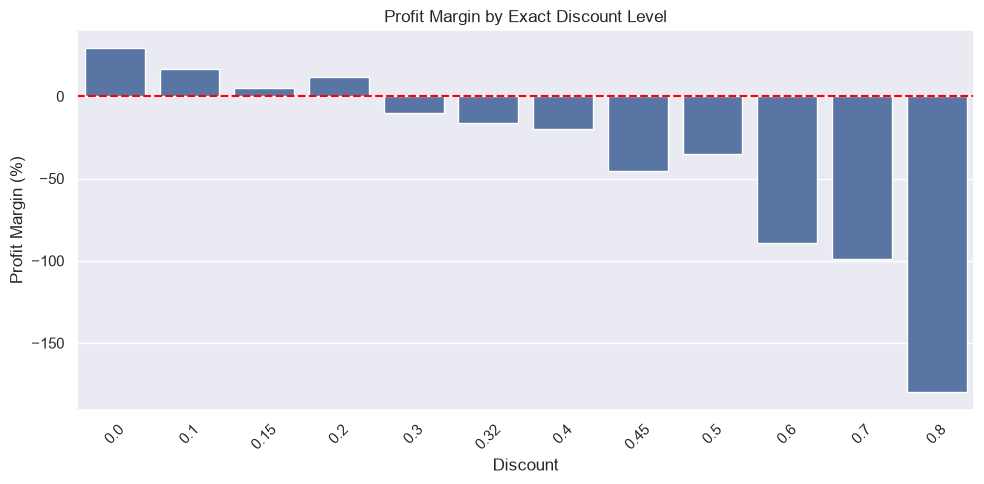

In [27]:
plt.figure(figsize=(10, 5))
sns.barplot(data=discount_analysis, x="discount", y="profit_margin_%")
plt.axhline(0, color="red", linestyle="--")
plt.title("Profit Margin by Exact Discount Level")
plt.xlabel("Discount")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


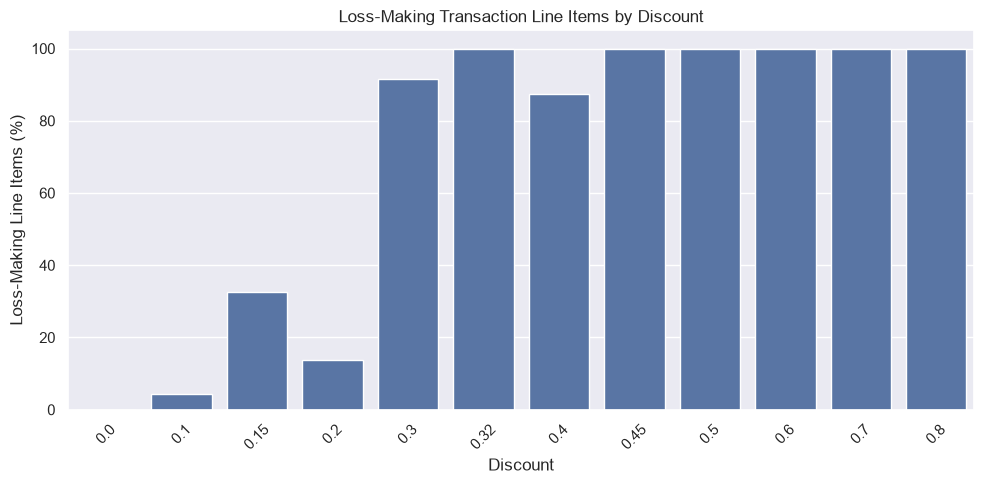

In [28]:
plt.figure(figsize=(10, 5))
sns.barplot(data=discount_analysis, x="discount", y="loss_rate_%")
plt.title("Loss-Making Transaction Line Items by Discount")
plt.xlabel("Discount")
plt.ylabel("Loss-Making Line Items (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 10.1 Discount band analysis

This additional view groups discount rates into the discount bands created during feature engineering.


In [29]:
discount_band_analysis = (
    df_clean.groupby("discount_level", observed=False)
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        average_profit=("profit", "mean"),
        transactions=("profit", "count"),
        loss_transactions=("profit", lambda values: (values < 0).sum())
    )
    .reset_index()
)

discount_band_analysis["profit_margin_%"] = (
    discount_band_analysis["total_profit"] /
    discount_band_analysis["total_sales"] * 100
).round(2)

discount_band_analysis["loss_rate_%"] = (
    discount_band_analysis["loss_transactions"] /
    discount_band_analysis["transactions"] * 100
).round(2)

display(discount_band_analysis.round(2))


,discount_level,total_sales,total_profit,average_profit,transactions,loss_transactions,profit_margin_%,loss_rate_%
0,No Discount,1087908.47,320987.60,66.90,4798,0,29.51,0.00
1,Low Discount,54369.35,9029.18,96.06,94,4,16.61,4.26
2,Moderate Discount,792152.89,91756.30,24.74,3709,519,11.58,13.99
3,High Discount,103226.66,-10369.28,-45.68,227,208,-10.05,91.63
4,Very High Discount,259543.49,-125006.78,-107.21,1166,1140,-48.16,97.77


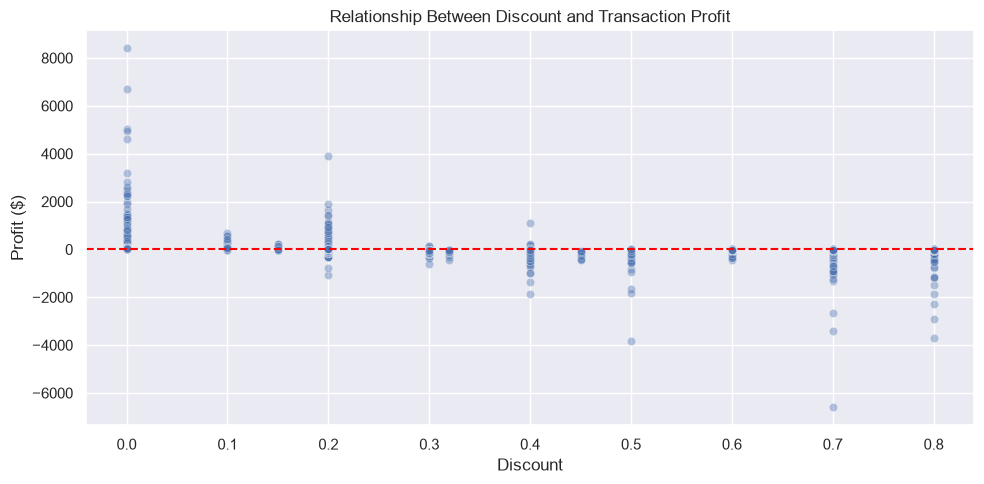

In [30]:
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df_clean,
    x="discount",
    y="profit",
    alpha=0.4
)
plt.axhline(0, color="red", linestyle="--")
plt.title("Relationship Between Discount and Transaction Profit")
plt.xlabel("Discount")
plt.ylabel("Profit ($)")
plt.tight_layout()
plt.show()


## 11. Monthly sales and profit trends

Aggregate performance by year and month. This view preserves the chronological sequence across the dataset.


In [31]:
monthly_analysis = (
    df_clean.groupby("year_month")
    .agg(
        total_sales=("sales", "sum"),
        total_profit=("profit", "sum"),
        total_orders=("order_id", "nunique"),
        total_quantity=("quantity", "sum")
    )
    .reset_index()
)

monthly_analysis["month_date"] = monthly_analysis["year_month"].dt.to_timestamp()
monthly_analysis = monthly_analysis.sort_values("month_date")

monthly_analysis["sales_growth_%"] = (
    monthly_analysis["total_sales"].pct_change() * 100
).round(2)

display(monthly_analysis.head(15).round(2))


C:\Users\Arshad Muhammed\AppData\Local\Temp\ipykernel_11932\2065278171.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_analysis.head(15).round(2))


,year_month,total_sales,total_profit,total_orders,total_quantity,month_date,sales_growth_%
0,2015-01,14236.90,2450.19,32,284.0,2015-01-01,NaN
1,2015-02,4519.89,862.31,28,159.0,2015-02-01,-68.25
2,2015-03,55691.01,498.73,71,585.0,2015-03-01,1132.13
3,2015-04,28295.34,3488.84,66,536.0,2015-04-01,-49.19
4,2015-05,23648.29,2738.71,69,466.0,2015-05-01,-16.42
5,2015-06,34595.13,4976.52,66,521.0,2015-06-01,46.29
6,2015-07,33946.39,-841.48,65,550.0,2015-07-01,-1.88
7,2015-08,27909.47,5318.10,72,609.0,2015-08-01,-17.78
8,2015-09,81777.35,8328.10,130,1000.0,2015-09-01,193.01
9,2015-10,31453.39,3448.26,78,573.0,2015-10-01,-61.54


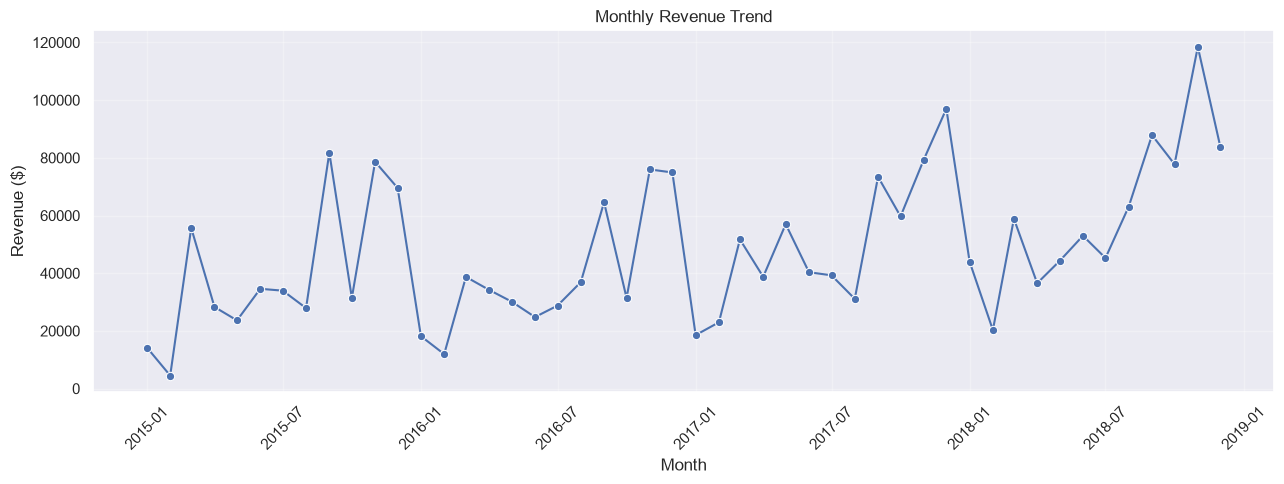

In [32]:
plt.figure(figsize=(13, 5))
sns.lineplot(
    data=monthly_analysis,
    x="month_date",
    y="total_sales",
    marker="o"
)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


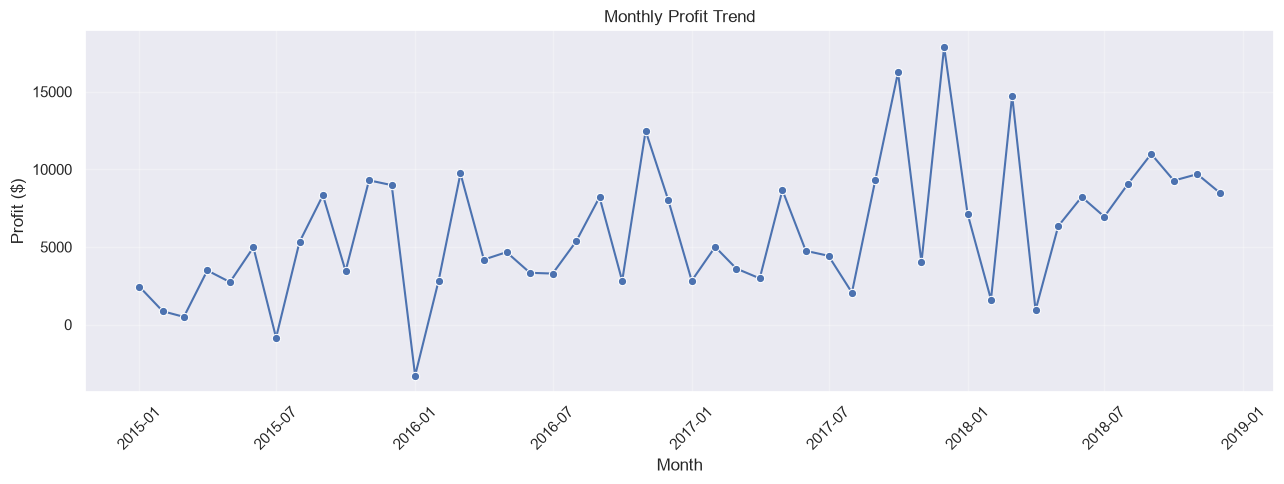

In [33]:
plt.figure(figsize=(13, 5))
sns.lineplot(
    data=monthly_analysis,
    x="month_date",
    y="total_profit",
    marker="o"
)
plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit ($)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 12. Monthly seasonality analysis

To compare calendar months fairly, calculate the average January performance across the available years, average February performance across the available years, and so on.


In [34]:
seasonality_analysis = (
    monthly_analysis.assign(
        calendar_month=monthly_analysis["month_date"].dt.month,
        month_name=monthly_analysis["month_date"].dt.month_name()
    )
    .groupby(["calendar_month", "month_name"])
    .agg(
        average_monthly_sales=("total_sales", "mean"),
        average_monthly_profit=("total_profit", "mean"),
        average_monthly_orders=("total_orders", "mean")
    )
    .reset_index()
    .sort_values("calendar_month")
)

display(seasonality_analysis.round(2))


,calendar_month,month_name,average_monthly_sales,average_monthly_profit,average_monthly_orders
0,1,January,23731.21,2283.61,44.50
1,2,February,14937.81,2573.65,40.50
2,3,March,51251.37,7148.67,88.50
3,4,April,34440.53,2896.86,85.75
4,5,May,38757.20,5602.83,92.25
5,6,June,38179.67,5321.45,91.00
6,7,July,36809.52,3458.17,84.50
7,8,August,39761.02,5444.23,85.25
8,9,September,76912.49,9214.37,172.00
9,10,October,50080.75,7946.01,104.25


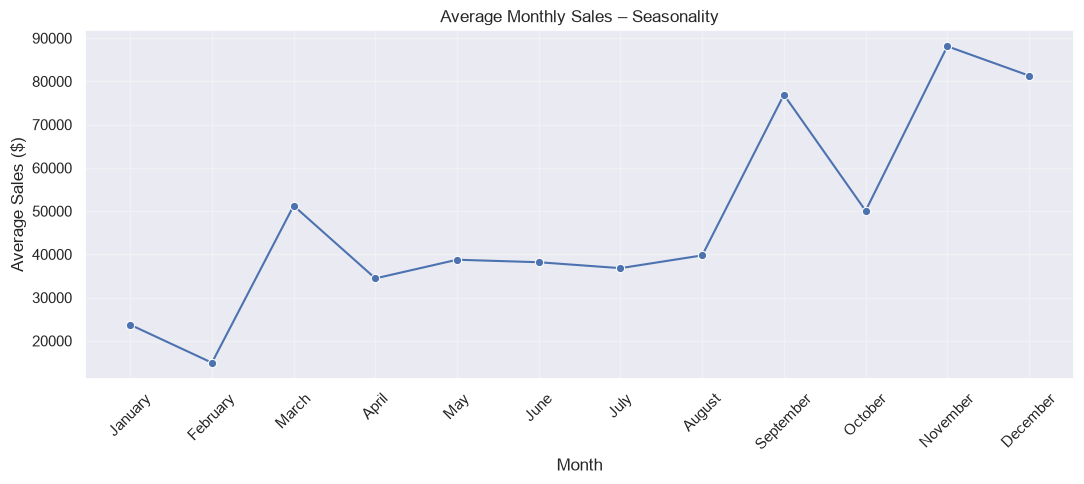

In [35]:
plt.figure(figsize=(11, 5))
sns.lineplot(
    data=seasonality_analysis,
    x="month_name",
    y="average_monthly_sales",
    marker="o"
)
plt.title("Average Monthly Sales – Seasonality")
plt.xlabel("Month")
plt.ylabel("Average Sales ($)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


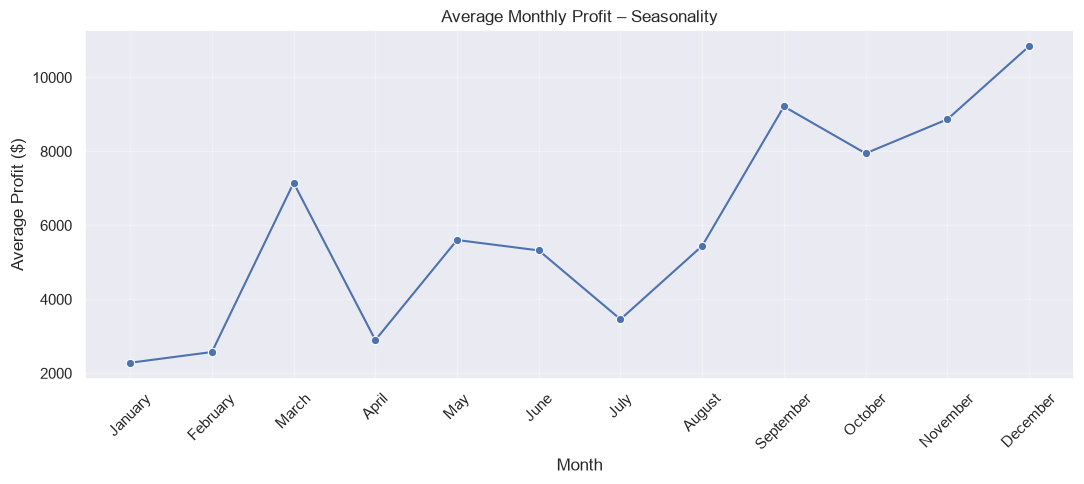

In [36]:
plt.figure(figsize=(11, 5))
sns.lineplot(
    data=seasonality_analysis,
    x="month_name",
    y="average_monthly_profit",
    marker="o"
)
plt.title("Average Monthly Profit – Seasonality")
plt.xlabel("Month")
plt.ylabel("Average Profit ($)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 13. Executive findings

The following findings are based on the analysis results produced in this notebook.

### Finding 1: Overall business performance

The business generated **$2,297,200.86 in revenue** and **$286,397.02 in profit**, achieving a profit margin of **12.47%** across 5,009 orders and 793 customers. Average order value was $458.61. A total of 1,871 transaction line items (18.72%) recorded negative profit.

**Recommendation:** Review loss-making products and transactions, discount policies and pricing to identify opportunities to improve profitability.

### Finding 2: Product category and subcategory performance

Technology generated the highest category revenue (**$836,154.03**) and profit (**$145,454.95**), with a 17.40% profit margin. Office Supplies achieved a 17.04% margin. Furniture generated $741,999.80 in revenue but had a margin of only 2.49%. At subcategory level, Copiers generated $55,617.82 profit, while Tables recorded a loss of $17,725.48.

**Recommendation:** Investigate Furniture pricing, discounts and cost structure, especially Tables and Bookcases. Protect the performance of strong subcategories such as Copiers, Accessories and Paper.

### Finding 3: Regional performance

West generated the highest regional revenue (**$725,457.82**) and profit (**$108,418.45**), with a 14.94% margin. Central had the lowest regional margin at **7.92%**, despite contributing 21.82% of revenue.

**Recommendation:** Investigate Central's product mix, pricing, discounts and costs. Assess whether practices used in the West can be adapted to improve Central's profitability.

### Finding 4: Customer spending and purchasing behaviour

The highest-spending customer, Sean Miller, generated $25,043.05 in sales but recorded a loss of $1,980.74. Other high-spending customers, including Tamara Chand and Raymond Buch, generated positive profit.

**Recommendation:** Evaluate customer value using both revenue and profit, rather than sales volume alone.

### Finding 5: Customer-level profitability

Tamara Chand was the most profitable customer, generating **$8,981.32** in profit. Cindy Stewart recorded the largest customer-level loss at **-$6,626.39**, despite generating $5,690.06 in sales.

**Recommendation:** Investigate customers with substantial negative profit and review their purchased products, discount levels and transaction costs. Prioritise retention of consistently profitable customers.

### Finding 6: Discount sensitivity

Transactions with a 30% discount had a negative profit margin of **-10.05%**, and 91.63% of line items at this discount level recorded losses. At discount levels of 32% and above, several discount levels showed a 100% loss rate.

**Recommendation:** Review high-discount approvals and evaluate discount decisions alongside product mix, pricing and costs. The results show an association, not proof that discounts alone cause losses.

### Finding 7: Monthly sales seasonality

November recorded the highest average monthly sales (**$88,114.77**) and average order volume (188.5 orders). December recorded the highest average monthly profit (**$10,847.30**). February had the lowest average sales, while January had the lowest average profit.

**Recommendation:** Prepare inventory, staffing and marketing ahead of the September–December peak period. Investigate weaker January and February performance while protecting profit margins.


## 14. Overall conclusion and business recommendations

The analysis shows that revenue growth does not always translate into strong profitability. Business performance differs by category, subcategory, region, customer and discount level.

### Priority recommendations

1. Review low-margin product categories and loss-making subcategories.
2. Investigate the causes of weak profitability in the Central region.
3. Monitor customer-level profit, not just customer spending.
4. Strengthen controls around high discount levels.
5. Prepare operations for stronger sales activity towards the end of the year.
6. Continue monitoring both revenue and profit when evaluating business performance.

### Analysis limitations

- The analysis is descriptive and identifies patterns and associations; it does not establish causation.
- The loss-making transaction rate is based on individual transaction line items, not unique orders.
- The seasonal averages compare calendar months across the years available in the dataset.
- Customer profitability is based on the profit values recorded in the dataset.


## 15. Export analysis tables

Save the principal analysis tables as CSV files in an `outputs` folder. The notebook itself remains the main project deliverable.


In [37]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

analysis_tables = {
    "executive_summary": executive_summary,
    "category_analysis": category_analysis,
    "subcategory_analysis": subcategory_analysis,
    "segment_analysis": segment_analysis,
    "region_analysis": region_analysis,
    "customer_analysis": customer_analysis,
    "top_10_customers": top_10_customers,
    "top_profitable_customers": top_profit_customers,
    "least_profitable_customers": lowest_profit_customers,
    "discount_analysis": discount_analysis,
    "discount_band_analysis": discount_band_analysis,
    "monthly_analysis": monthly_analysis,
    "seasonality_analysis": seasonality_analysis
}

for filename, table in analysis_tables.items():
    table.to_csv(output_dir / f"{filename}.csv", index=False)

print(f"Exported {len(analysis_tables)} analysis tables to: {output_dir.resolve()}")


Exported 13 analysis tables to: C:\Users\Arshad Muhammed\OneDrive\Documents\Datheon\outputs


---

**End of project – Superstore Sales Analysis**

To reproduce the analysis, restart the kernel and run all cells from the beginning. Confirm that the dataset path is correct before running the notebook.
